### **Movie Recommendation System**

**For The Dataset we reffered the kaggle.com**

**It contains 6,234 Rows and 12 Columns**

**Link For The Dataset---->**
**https://www.kaggle.com/code/abhichoudhury/a-simple-movie-recommender?select=netflix_titles.csv**

**Link of vedio-->**
**https://drive.google.com/file/d/1melYS94lkLpGG8LC6oobDpV6RxrR1_2h/view?usp=drivesdk**

**Link of Presentation-->**
**https://acrobat.adobe.com/id/urn:aaid:sc:AP:4792cbc4-dde9-4b72-9ac9-6f3603b8458d**

Our AI101 project **"Movie Recommender"** is based on **Logistic Regression** and satisfies all the needs such as it contains the following features:-
1. Data pre-processing
2. Data Split in Training and Testing
3. Training Plots
4. Evaluation Metrics (Like Confusion Matrix,Precision,Recal etc)
5. It also gives statistical info of the given data

**1. Installing the required libraries**

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


**2. Importing the libraries**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_squared_error,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")


Checking the directory in which we have our enviroment


In [3]:
import os

print(os.getcwd())

c:\Users\HP\OneDrive\Desktop\New folder\Git-AI101-Mini project\AI101-Mini-project\Codes


**3. Loading data from .csv file**

In [4]:
df = pd.read_csv("netflix_titles.csv")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

FileNotFoundError: [Errno 2] No such file or directory: 'netflix_titles.csv'

**4. Explainin the Data**

In [ ]:
print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nContent Type Distribution:")
print(df["type"].value_counts())

print("\nMost Common Genres:")
print(df["listed_in"].value_counts().head(10))


Statistical Summary:
            show_id  release_year
count  6.234000e+03    6234.00000
mean   7.670368e+07    2013.35932
std    1.094296e+07       8.81162
min    2.477470e+05    1925.00000
25%    8.003580e+07    2013.00000
50%    8.016337e+07    2016.00000
75%    8.024489e+07    2018.00000
max    8.123573e+07    2020.00000

Missing Values:
show_id            0
type               0
title              0
director        1969
cast             570
country          476
date_added        11
release_year       0
rating            10
duration           0
listed_in          0
description        0
dtype: int64

Duplicate Records:
0

Content Type Distribution:
type
Movie      4265
TV Show    1969
Name: count, dtype: int64

Most Common Genres:
listed_in
Documentaries                                       299
Stand-Up Comedy                                     273
Dramas, International Movies                        248
Dramas, Independent Movies, International Movies    186
Comedies, Dramas, Inte

**5. Data preprocessing**


In [ ]:
# Remove duplicate records

df = df.drop_duplicates(subset="show_id")

# Remove rows having missing important information

df = df.dropna(
    subset=["show_id", "title", "type", "listed_in", "release_year"]
)

# Clean text columns

df["title"] = df["title"].astype(str).str.strip()

df["type"] = df["type"].astype(str).str.strip()

df["listed_in"] = df["listed_in"].astype(str).str.strip()

# Convert release year into numeric format

df["release_year"] = pd.to_numeric(
    df["release_year"],
    errors="coerce"
)

df = df.dropna(subset=["release_year"])

# Keep only Movie and TV Show records

df = df[df["type"].isin(["Movie", "TV Show"])].copy()

# Extract duration number for statistical analysis

df["duration_value"] = pd.to_numeric(
    df["duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

print("\nDataset After Preprocessing:")
print(df.head())

print("\nRemaining Missing Values:")
print(df.isnull().sum())



Dataset After Preprocessing:
    show_id     type                                    title  \
0  81145628    Movie  Norm of the North: King Sized Adventure   
1  80117401    Movie               Jandino: Whatever it Takes   
2  70234439  TV Show                       Transformers Prime   
3  80058654  TV Show         Transformers: Robots in Disguise   
4  80125979    Movie                             #realityhigh   

                   director  \
0  Richard Finn, Tim Maltby   
1                       NaN   
2                       NaN   
3                       NaN   
4          Fernando Lebrija   

                                                cast  \
0  Alan Marriott, Andrew Toth, Brian Dobson, Cole...   
1                                   Jandino Asporaat   
2  Peter Cullen, Sumalee Montano, Frank Welker, J...   
3  Will Friedle, Darren Criss, Constance Zimmer, ...   
4  Nesta Cooper, Kate Walsh, John Michael Higgins...   

                                    country         dat

**6. Statistical information of data**

In [ ]:
print("\nMean Release Year:")
print(df["release_year"].mean())

print("\nMedian Release Year:")
print(df["release_year"].median())

print("\nStandard Deviation:")
print(df["release_year"].std())

print("\nVariance:")
print(df["release_year"].var())

# Duration statistics for movies only
# Do not mix movie minutes with TV show seasons

movie_duration = df.loc[
    df["type"] == "Movie",
    "duration_value"
].dropna()

print("\nAverage Movie Duration:")
print(movie_duration.mean())

print("\nMedian Movie Duration:")
print(movie_duration.median())

print("\nMovie Duration Standard Deviation:")
print(movie_duration.std())

# Covariance and correlation

numeric_analysis = df.loc[
    df["type"] == "Movie",
    ["release_year", "duration_value"]
].dropna()

print("\nMovie Covariance Matrix:")
print(numeric_analysis.cov())

print("\nMovie Correlation Matrix:")
print(numeric_analysis.corr())


Mean Release Year:
2013.3593198588387

Median Release Year:
2016.0

Standard Deviation:
8.811620351521556

Variance:
77.64465321934887

Average Movie Duration:
99.10082063305978

Median Movie Duration:
98.0

Movie Duration Standard Deviation:
28.074857416065484

Movie Covariance Matrix:
                release_year  duration_value
release_year       94.776192      -46.555896
duration_value    -46.555896      788.197619

Movie Correlation Matrix:
                release_year  duration_value
release_year        1.000000       -0.170336
duration_value     -0.170336        1.000000


**7. Getting knowledge about what Genre the person likes**


In [ ]:
# Split genres separated by commas

df["genre_list"] = df["listed_in"].apply(
    lambda x: [
        genre.strip()
        for genre in x.split(",")
        if genre.strip()
    ]
)

# Convert genres into numerical features

mlb = MultiLabelBinarizer()

genre_array = mlb.fit_transform(
    df["genre_list"]
)

genre_df = pd.DataFrame(
    genre_array,
    columns=mlb.classes_,
    index=df.index
)

print("\nEncoded Genre Features:")
print(genre_df.head())

print("\nAvailable Genres:")
print(mlb.classes_)


Encoded Genre Features:
   Action & Adventure  Anime Features  Anime Series  British TV Shows  \
0                   0               0             0                 0   
1                   0               0             0                 0   
2                   0               0             0                 0   
3                   0               0             0                 0   
4                   0               0             0                 0   

   Children & Family Movies  Classic & Cult TV  Classic Movies  Comedies  \
0                         1                  0               0         1   
1                         0                  0               0         0   
2                         0                  0               0         0   
3                         0                  0               0         0   
4                         0                  0               0         1   

   Crime TV Shows  Cult Movies  ...  TV Action & Adventure  TV Comedies  \
0   

**8. Checking Correlation**


Correlation Matrix:
                              Action & Adventure  Anime Features  \
Action & Adventure                      1.000000        0.184747   
Anime Features                          0.184747        1.000000   
Anime Series                           -0.045008       -0.011793   
British TV Shows                       -0.060762       -0.015921   
Children & Family Movies               -0.048420        0.025974   
Classic & Cult TV                      -0.020231       -0.005301   
Classic Movies                          0.042343        0.006470   
Comedies                                0.033327       -0.039753   
Crime TV Shows                         -0.080921       -0.021203   
Cult Movies                             0.039248       -0.008045   
Documentaries                          -0.109216       -0.029540   
Docuseries                             -0.070441       -0.018457   
Dramas                                  0.014376       -0.050589   
Faith & Spirituality       

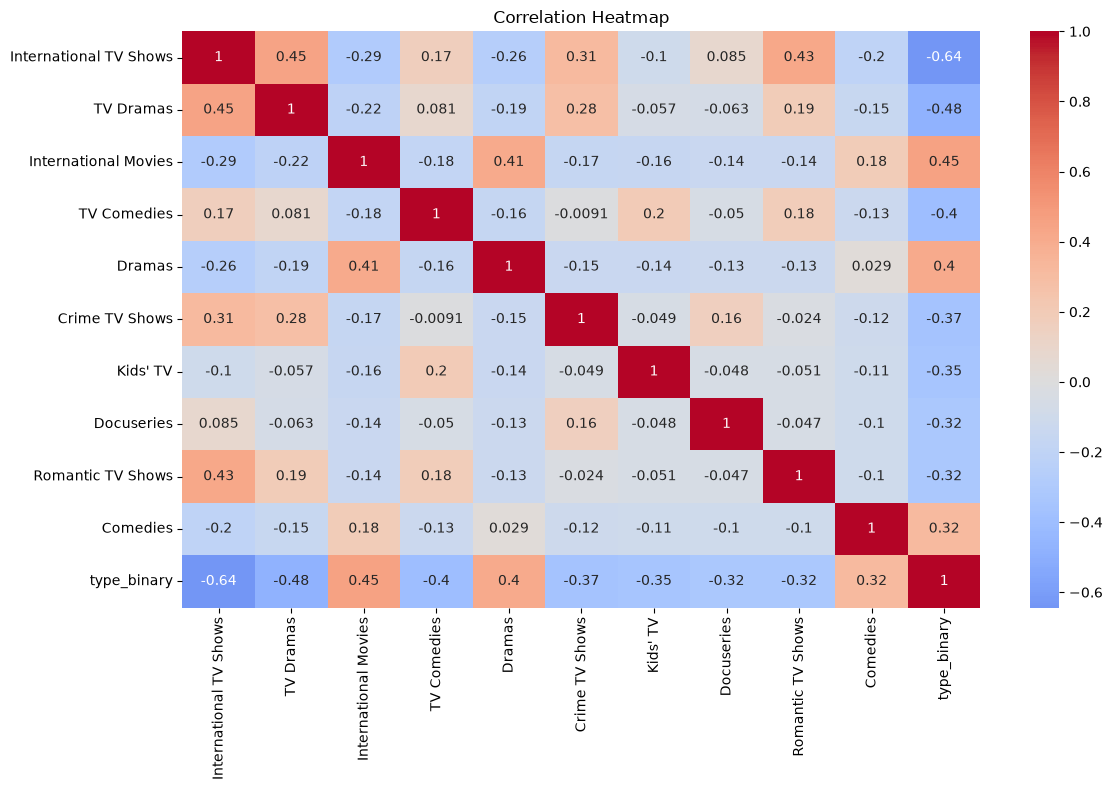

In [ ]:
analysis_df = genre_df.copy()

analysis_df["release_year"] = df["release_year"]

# Convert content type into binary values for analysis

analysis_df["type_binary"] = (
    df["type"] == "Movie"
).astype(int)

correlation = analysis_df.corr()

covariance = analysis_df.cov()

print("\nCorrelation Matrix:")
print(correlation)

print("\nCovariance Matrix:")
print(covariance)

# Correlation with movie type

type_correlation = correlation[
    "type_binary"
].sort_values(ascending=False)

print("\nGenre Correlation With Movie Type:")
print(type_correlation)


# Plot correlation heatmap for selected variables

top_correlated = type_correlation.drop(
    "type_binary"
).abs().sort_values(ascending=False).head(10).index

heatmap_columns = list(top_correlated) + ["type_binary"]

plt.figure(figsize=(12, 8))

sns.heatmap(
    analysis_df[heatmap_columns].corr(),
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.show()

**9. Analysing Features**

In [ ]:
# Input features

X = genre_df.copy()

# Add release year

X["release_year"] = df["release_year"]

# Target variable
# Movie = 1
# TV Show = 0

y = (
    df["type"] == "Movie"
).astype(int)

# Select the top 15 features

k = min(15, X.shape[1])

selector = SelectKBest(
    score_func=chi2,
    k=k
)

# NOTE:
# Feature selection will be fitted after data splitting.
# This avoids information leakage.

**10. Data Splitting**

In [ ]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (4987, 43)
Testing Data: (1247, 43)


**11. Feature Selection**

In [ ]:
# FEATURE SELECTION

selector = SelectKBest(
    score_func=chi2,
    k=k
)

X_train_selected = selector.fit_transform(
    X_train,
    y_train
)

X_test_selected = selector.transform(
    X_test
)

selected_features = X_train.columns[
    selector.get_support()
]

print("Selected Features:")
print(selected_features)

Selected Features:
Index(['Action & Adventure', 'British TV Shows', 'Comedies', 'Crime TV Shows',
       'Documentaries', 'Docuseries', 'Dramas', 'International Movies',
       'International TV Shows', 'Kids' TV', 'Korean TV Shows', 'Reality TV',
       'Romantic TV Shows', 'TV Comedies', 'TV Dramas'],
      dtype='str')


**12. Normalization**

In [ ]:
# Normalization

scaler = StandardScaler()

# Fit on training data
X_train_scaled = scaler.fit_transform(
    X_train_selected
)

# Transform testing data
X_test_scaled = scaler.transform(
    X_test_selected
)

**13. Logistic Regression and Training of Model**

In [ ]:
# Training Function

def train_model(X_train, y_train):

    model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

    model.fit(X_train, y_train)

    return model


In [ ]:
model = train_model(
    X_train_scaled,
    y_train
)

**14. Testing of model**

In [ ]:
def test_model(model, X_test):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    return predictions, probabilities


y_pred, y_probability = test_model(
    model,
    X_test_scaled
)

print("\nPredictions:")
print(y_pred[:10])

print("\nProbabilities:")
print(y_probability[:10])


Predictions:
[1 0 1 1 1 1 1 1 0 0]

Probabilities:
[9.97126945e-01 2.70979142e-06 8.65787309e-01 9.99866344e-01
 9.96895923e-01 8.65787309e-01 9.99997515e-01 9.99876318e-01
 1.48317049e-03 4.61812669e-05]


**15. Metrics Evaluation**

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

# RMSE Calculation

y_probability = model.predict_proba(
    X_test_scaled
)[:, 1]

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_probability
    )
)




auc = roc_auc_score(
    y_test,
    y_probability
)

print("\n========== MODEL EVALUATION ==========")

print("Accuracy:", accuracy)

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

print("RMSE:", rmse)

print("ROC AUC:", auc)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["TV Show", "Movie"],
        zero_division=0
    )
)


========== MODEL EVALUATION ==========
Accuracy: 0.9903769045709703
Precision: 0.9861271676300578
Recall: 1.0
F1 Score: 0.9930151338766007
RMSE: 0.09598813370548209
ROC AUC: 0.9975363155420404

Classification Report:
              precision    recall  f1-score   support

     TV Show       1.00      0.97      0.98       394
       Movie       0.99      1.00      0.99       853

    accuracy                           0.99      1247
   macro avg       0.99      0.98      0.99      1247
weighted avg       0.99      0.99      0.99      1247



**16. Confusion Matrix Creation**

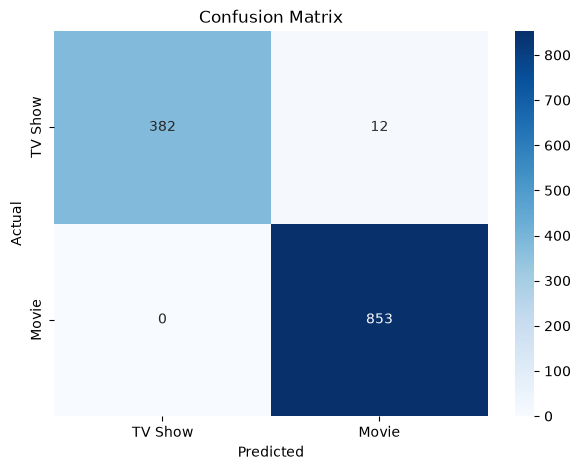

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["TV Show", "Movie"],
    yticklabels=["TV Show", "Movie"]
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

**17. Data Visualization  And Model Plots**

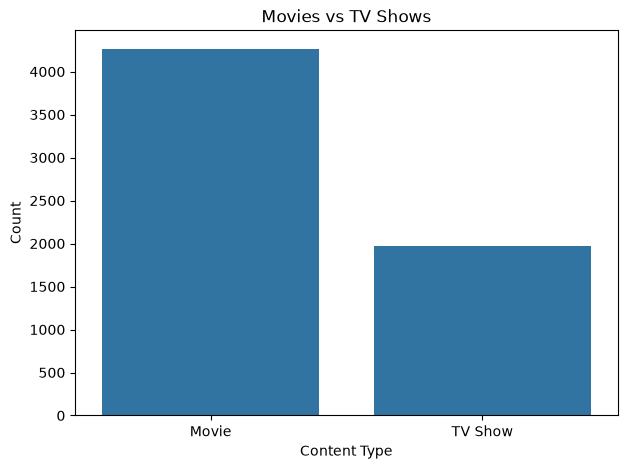

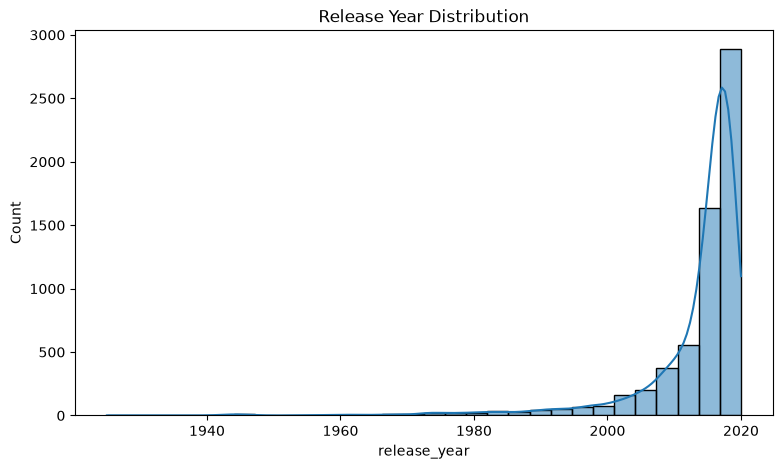

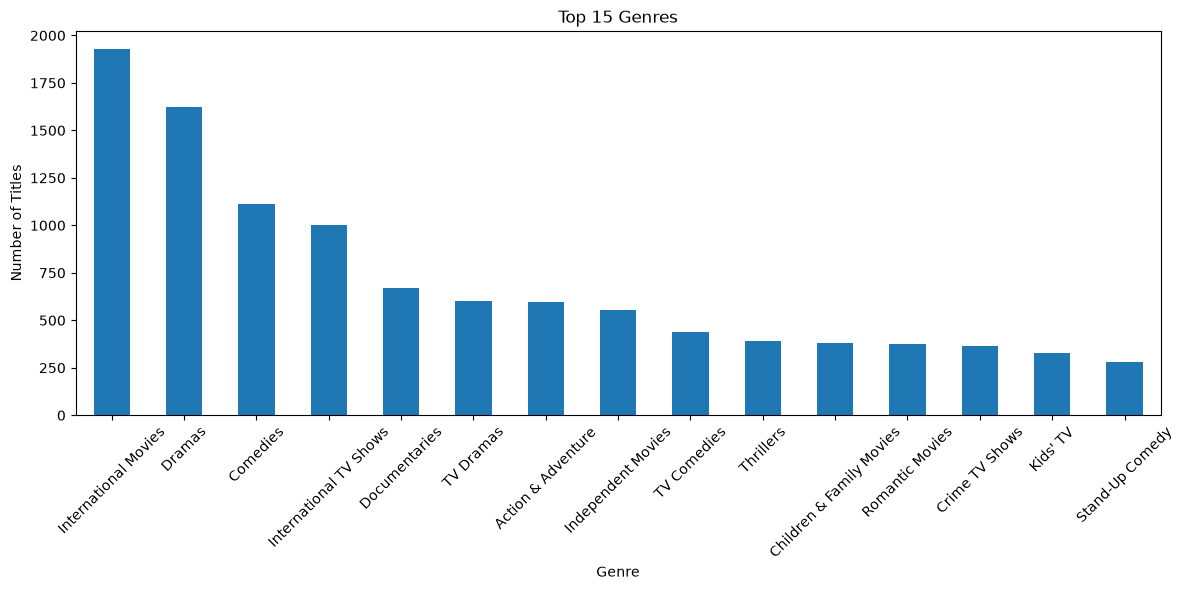

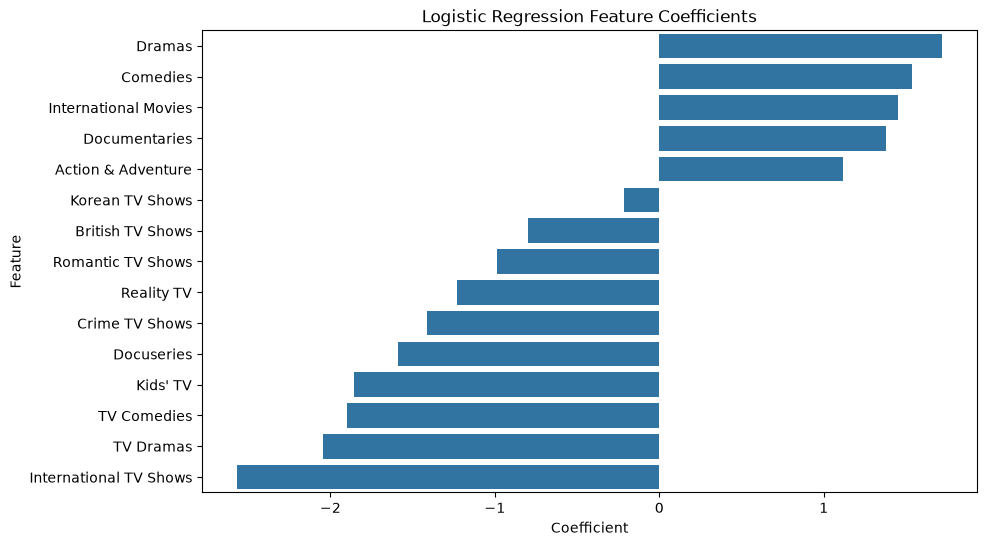

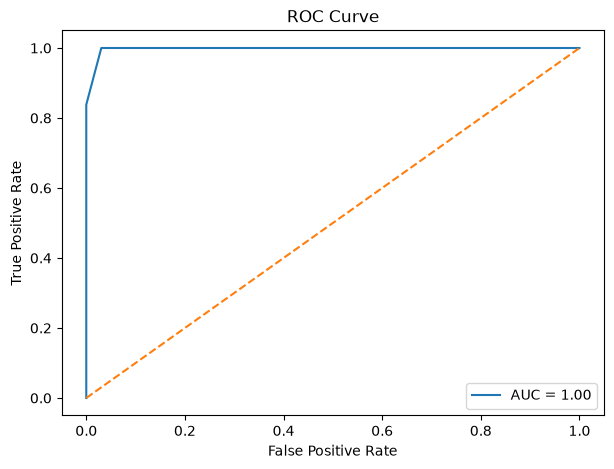

In [ ]:
# Plot 1: Movies vs TV Shows

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="type"
)

plt.title("Movies vs TV Shows")

plt.xlabel("Content Type")

plt.ylabel("Count")

plt.show()


# Plot 2: Release Year Distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    df["release_year"],
    bins=30,
    kde=True
)

plt.title("Release Year Distribution")

plt.show()


# Plot 3: Most Common Genres

genre_counts = genre_df.sum().sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))

genre_counts.head(15).plot(
    kind="bar"
)

plt.title("Top 15 Genres")

plt.xlabel("Genre")

plt.ylabel("Number of Titles")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# Plot 4: Logistic Regression Coefficients

coefficients = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression Feature Coefficients")

plt.show()


# Plot 5: ROC Curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.2f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

### **18. Movie Recommendation**

In [ ]:
# Select only movies

movies_df = df[
    df["type"] == "Movie"
].copy()


# Function to calculate Jaccard Similarity

def calculate_similarity(genres1, genres2):

    set1 = set(genres1)

    set2 = set(genres2)

    intersection = len(set1.intersection(set2))

    union = len(set1.union(set2))

    if union == 0:
        return 0

    return intersection / union


# Main Recommendation Function

def recommend_movies(movie_name, n=5):

    # Find the selected movie

    selected_movie = movies_df[
        movies_df["title"].str.lower() == movie_name.lower()
    ]

    # Check whether movie exists

    if selected_movie.empty:

        print("Movie Not Found!")

        return None

    # Get selected movie genres

    selected_genres = selected_movie.iloc[0]["genre_list"]

    print("\nSelected Movie:", movie_name)

    print("Genres:", selected_genres)

    # Create a copy of movie dataset

    recommendations = movies_df.copy()

    # Calculate similarity with every other movie

    recommendations["similarity"] = recommendations[
        "genre_list"
    ].apply(
        lambda genres: calculate_similarity(
            selected_genres,
            genres
        )
    )

    # Remove the selected movie

    recommendations = recommendations[
        recommendations["show_id"] != selected_movie.iloc[0]["show_id"]
    ]

    # Sort according to similarity

    recommendations = recommendations.sort_values(
        by="similarity",
        ascending=False
    )

    # Select top recommendations

    result = recommendations[
        [
            "title",
            "release_year",
            "listed_in",
            "similarity"
        ]
    ].head(n)

    print("\n========== RECOMMENDED MOVIES ==========")

    print(result.to_string(index=False))

    return result



**19. Testing The Recommendation System**

In [ ]:
recommend_movies("The Conjuring", 5)
recommend_movies("Inception", 5)
recommend_movies("3 Idiots", 5)



Selected Movie: The Conjuring
Genres: ['Horror Movies', 'Thrillers']

========== RECOMMENDED MOVIES ==========
        title  release_year                listed_in  similarity
Before I Wake          2016 Horror Movies, Thrillers         1.0
 The Detained          2017 Horror Movies, Thrillers         1.0
      Gothika          2003 Horror Movies, Thrillers         1.0
     Clinical          2017 Horror Movies, Thrillers         1.0
  Cabin Fever          2016 Horror Movies, Thrillers         1.0

Selected Movie: Inception
Genres: ['Action & Adventure', 'Sci-Fi & Fantasy', 'Thrillers']

========== RECOMMENDED MOVIES ==========
              title  release_year                                       listed_in  similarity
          Limitless          2011 Action & Adventure, Sci-Fi & Fantasy, Thrillers    1.000000
Season of the Witch          2011            Action & Adventure, Sci-Fi & Fantasy    0.666667
      Alien Warfare          2019            Action & Adventure, Sci-Fi & Fantasy  

,title,release_year,listed_in,similarity
4497,Honeymoon Travels Pvt. Ltd.,2007,"Comedies, Dramas, International Movies",1.0
4490,Dil Dhadakne Do,2015,"Comedies, Dramas, International Movies",1.0
4489,Dil Chahta Hai,2001,"Comedies, Dramas, International Movies",1.0
871,Judge Singh LLB,2015,"Comedies, Dramas, International Movies",1.0
869,Jatt James Bond,2014,"Comedies, Dramas, International Movies",1.0


**NOTE:
 Some Parts are Modified by the Help of AI as those were beyond our limits and some parts are itself written by me such as the statistical part , the logistic regression part etc.** 



# **&#10084; Hope So You Liked Our Project &#10084;**